# 04 — PCA Visualisation & Clustering / Rule Robustness

This notebook evaluates:
1. **2D PCA & Explained Variance** (`src.pca_plot.plot_pca`) on the scaled user profiles (`user_profiles.parquet`), inspecting cluster separation, top positive/negative feature loadings for PC1 and PC2, and cumulative variance across all components[cite: 1, 6].
2. **Cluster Stability** (`src.robustness.cluster_stability`) across random seeds (`0–9`) via Adjusted Rand Index (ARI) and cross-tabulations against `k - 1` and `k + 1`[cite: 2].
3. **Association Rule Stability** (`src.robustness.rule_stability`) across multiple `min_support` thresholds using `src.rules.mine_rules` to identify persistent vs. fragile rules[cite: 2, 3].

In [1]:
import sys
sys.path.append('..')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

from src.pca_plot import plot_pca
from src.robustness import cluster_stability, rule_stability
from src.rules import mine_rules

SEED = 42
DATA = Path('../data')
FIG = Path('../figures')
FIG.mkdir(parents=True, exist_ok=True)

# Main K-Means cluster count (adjust if a different k was selected in 02_clustering)
MAIN_K = 4
MIN_CONFIDENCE = 0.50
SUPPORTS = [0.01, 0.02, 0.05]
MAX_RULE_USERS = 10_000

## 1. Load Scaled User Profiles & Obtain Cluster Labels

`user_profiles.parquet` already contains standardized features (`mean = 0`, `std = 1`)[cite: 6], so `plot_pca` and `cluster_stability` use them directly without re-scaling[cite: 1, 2]. If a saved cluster-label file exists in `../data/`, it is loaded; otherwise K-Means (`n_init=10`, `random_state=SEED`) is fit with `MAIN_K`.

In [2]:
profiles_scaled = pd.read_parquet(DATA / 'user_profiles.parquet')
print('Scaled profiles shape:', profiles_scaled.shape)

label_candidates = [
    DATA / 'cluster_labels.parquet',
    DATA / 'user_clusters.parquet',
    DATA / 'clusters.parquet',
]
existing_label_file = next((p for p in label_candidates if p.exists()), None)

user_col = next(c for c in ('userId', 'user_id', 'user') if c in profiles_scaled.columns)
feature_cols = [
    c for c in profiles_scaled.columns
    if c != user_col and pd.api.types.is_numeric_dtype(profiles_scaled[c])
]

if existing_label_file is not None:
    labels_df = pd.read_parquet(existing_label_file)
    print('Loaded cluster labels from:', existing_label_file)
else:
    km_main = KMeans(n_clusters=MAIN_K, n_init=10, random_state=SEED)
    cluster_pred = km_main.fit_predict(profiles_scaled[feature_cols].to_numpy(dtype=float))
    labels_df = pd.DataFrame({
        user_col: profiles_scaled[user_col],
        'cluster': cluster_pred,
    })
    print(f'Fitted KMeans (k={MAIN_K}) for {len(labels_df):,} users.')

lbl_cluster_col = next(c for c in ('cluster', 'cluster_label', 'label') if c in labels_df.columns)
print('Cluster distribution:')
print(labels_df[lbl_cluster_col].value_counts().sort_index())

Scaled profiles shape: (200948, 21)


Fitted KMeans (k=4) for 200,948 users.
Cluster distribution:
cluster
0    45933
1    71577
2    20611
3    62827
Name: count, dtype: int64


## 2. 2D PCA Visualisation & Feature Loadings

PC1 explained variance: 21.37%
PC2 explained variance: 18.68%
Combined PC1 + PC2 explained variance: 40.05%


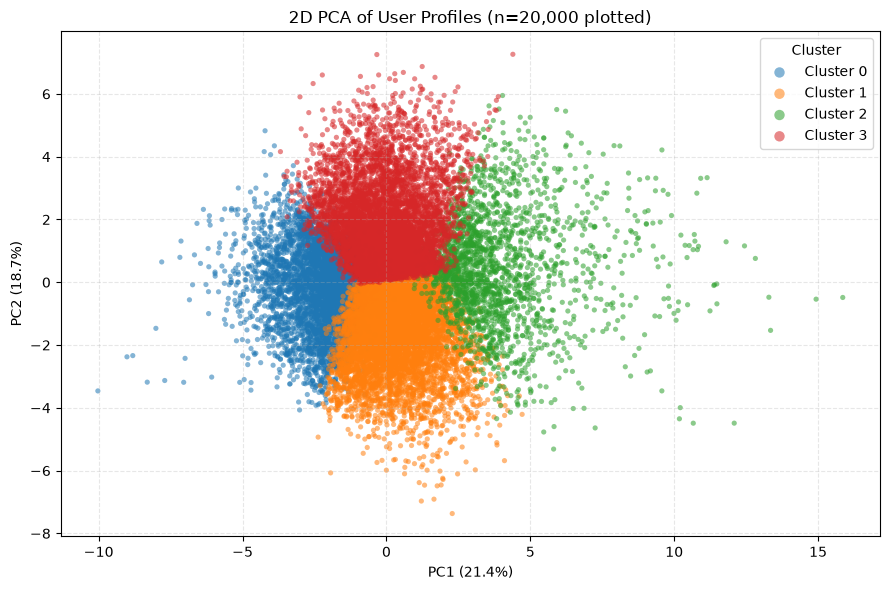

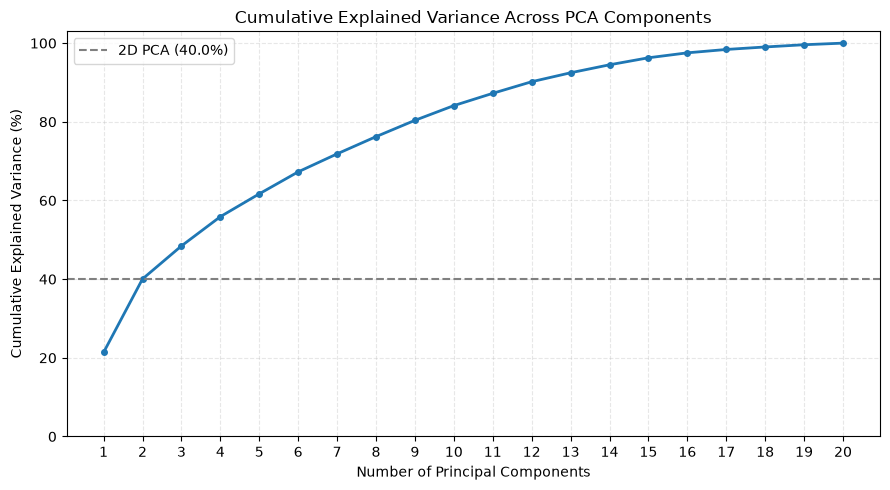


Top 5 positive and negative loadings per component:


feature                       loading               
direction      top_5_negative top_5_positive top_5_negative top_5_positive
component rank                                                            
PC1       1             Crime       Children      -0.315488       0.408013
          2          Thriller      Animation      -0.281783       0.359969
          3           Mystery        Fantasy      -0.259528       0.335432
          4             Drama        Musical      -0.244203       0.287766
          5               War         Comedy      -0.159393        0.25259
PC2       1           Romance         Action      -0.373938       0.451578
          2             Drama         Sci-Fi      -0.291346       0.415542
          3            Comedy      Adventure      -0.266994       0.386164
          4           Musical       Thriller      -0.139202       0.259382
          5       Documentary        Fantasy      -0.110439        0.16979

In [3]:
loadings_df, pca_plot_df = plot_pca(
    profiles_df=profiles_scaled,
    labels_df=labels_df,
    max_plot_users=20_000,
    random_state=SEED,
    output_dir=FIG,
    show=True,
)

print("\nTop 5 positive and negative loadings per component:")
display(
    loadings_df.pivot(
        index=["component", "rank"],
        columns="direction",
        values=["feature", "loading"],
    )
)

## 3. Cluster Stability Across Seeds & Neighboring `k`

Sampling 50,000 of 200,948 users with seed=42 for runtime stability.


Cluster stability across seeds (k=4) -> Mean ARI: 0.9490 | Min ARI: 0.9341



--- Main clusters (k=4) vs. k-1 (3) ---
k_3          0      1      2
main_k_4                    
0            3   4298   7093
1         1370  15960    419
2         5179      0      0
3         2169     70  13439



--- Main clusters (k=4) vs. k+1 (5) ---
k_5          0      1     2     3     4
main_k_4                               
0            0    589  9469  1312    24
1          158  10090    10  7491     0
2         4803     14     1   196   165
3           28      0   394  7090  8166


,seed,ari
0,0,0.934351
1,1,0.955280
2,2,0.949569
3,3,0.960668
4,4,0.938969
5,5,0.934109
6,6,0.952749
7,7,0.954035
8,8,0.953983
9,9,0.956272


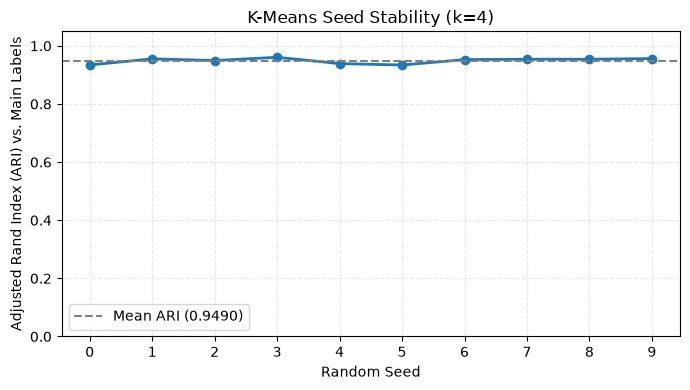

In [4]:
ari_df, k_crosstabs = cluster_stability(
    profiles_df=profiles_scaled,
    main_labels_df=labels_df,
    k=MAIN_K,
    seeds=range(10),
    max_users=50_000,
    random_state=SEED,
    n_init=10,
    return_tables=True,
)

display(ari_df)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ari_df['seed'], ari_df['ari'], marker='o', linewidth=2)
ax.axhline(ari_df['ari'].mean(), linestyle='--', color='gray', label=f"Mean ARI ({ari_df['ari'].mean():.4f})")
ax.set_title(f'K-Means Seed Stability (k={MAIN_K})')
ax.set_xlabel('Random Seed')
ax.set_ylabel('Adjusted Rand Index (ARI) vs. Main Labels')
ax.set_xticks(ari_df['seed'])
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / 'robustness_cluster_ari.png', dpi=300)
plt.show()

## 4. Association Rule Stability Across Support Thresholds

`clean_ratings.parquet` stores `userId`, `movieId`, and `rating`, while `movies_clean.parquet` stores one-hot genre flags per `movieId`[cite: 5]. We attach a pipe-delimited `genres` column (`Action|Sci-Fi`) so `mine_rules` can build user genre-share transactions cleanly[cite: 3, 5].

In [5]:
sample_path = DATA / 'sample_ratings.parquet'
ratings_base = pd.read_parquet(sample_path if sample_path.exists() else DATA / 'clean_ratings.parquet')
movies_onehot = pd.read_parquet(DATA / 'movies_clean.parquet')

genre_cols = [c for c in movies_onehot.columns if c != 'movieId']
genre_matrix = movies_onehot[genre_cols].to_numpy(dtype=bool)
genre_labels = np.array(genre_cols, dtype=object)

movie_genres_str = pd.Series(
    ['|'.join(genre_labels[row]) for row in genre_matrix],
    index=movies_onehot['movieId'],
    name='genres',
)

ratings_with_genres = ratings_base.join(movie_genres_str, on='movieId')
ratings_with_genres = ratings_with_genres.dropna(subset=['genres'])
ratings_with_genres = ratings_with_genres[ratings_with_genres['genres'] != '']

rng = np.random.default_rng(SEED)
available_users = ratings_with_genres['userId'].unique()
rule_users = rng.choice(
    available_users,
    size=min(MAX_RULE_USERS, len(available_users)),
    replace=False,
)
print(f'Evaluating rule stability on {len(rule_users):,} users across supports {SUPPORTS} (min_confidence={MIN_CONFIDENCE})...')

Evaluating rule stability on 10,000 users across supports [0.01, 0.02, 0.05] (min_confidence=0.5)...


In [6]:
rules_stability_df = rule_stability(
    ratings_df=ratings_with_genres,
    user_ids=rule_users,
    supports=SUPPORTS,
    min_confidence=MIN_CONFIDENCE,
    mine_rules_fn=mine_rules,
)

print('\nStable rules (present at all tested support thresholds):')
display(rules_stability_df[rules_stability_df['stable']].reset_index(drop=True))

print('\nFragile rules (present at lowest support, absent at higher support(s)):')
display(rules_stability_df[rules_stability_df['fragile']].reset_index(drop=True))

Rule stability across supports [0.01, 0.02, 0.05] -> Stable rules: 1130 | Fragile rules: 4307

Stable rules (present at all tested support thresholds):


,rule,present_0.01,lift_0.01,present_0.02,lift_0.02,present_0.05,lift_0.05,stable,fragile
0,"Animation, Comedy → Adventure, Children",True,8.450637,True,8.450637,True,8.450637,True,False
1,"Adventure, Children → Animation, Comedy",True,8.450637,True,8.450637,True,8.450637,True,False
2,"Adventure, Animation, Comedy → Children",True,8.028499,True,8.028499,True,8.028499,True,False
3,"Children → Adventure, Animation, Comedy",True,8.028499,True,8.028499,True,8.028499,True,False
4,"Animation → Adventure, Children, Comedy",True,8.024439,True,8.024439,True,8.024439,True,False
...,...,...,...,...,...,...,...,...,...
1125,"Adventure, Drama, Fantasy → Thriller",True,0.740881,True,0.740881,True,0.740881,True,False
1126,Fantasy → Thriller,True,0.728994,True,0.728994,True,0.728994,True,False
1127,"Comedy, Drama, Romance → Thriller",True,0.726846,True,0.726846,True,0.726846,True,False
1128,"Comedy, Romance → Thriller",True,0.724128,True,0.724128,True,0.724128,True,False



Fragile rules (present at lowest support, absent at higher support(s)):


,rule,present_0.01,lift_0.01,present_0.02,lift_0.02,present_0.05,lift_0.05,stable,fragile
0,"Children, Fantasy, Sci-Fi → Action, Adventure,...",True,13.141835,False,NaN,False,NaN,False,True
1,"Adventure, Children, Fantasy, Sci-Fi → Action,...",True,12.979590,False,NaN,False,NaN,False,True
2,"Children, Fantasy, Sci-Fi → Action, Animation,...",True,12.979590,False,NaN,False,NaN,False,True
3,"Children, Drama, Fantasy, Sci-Fi → Action, Adv...",True,12.923528,False,NaN,False,NaN,False,True
4,"Adventure, Children, Drama, Fantasy, Sci-Fi → ...",True,12.737243,False,NaN,False,NaN,False,True
...,...,...,...,...,...,...,...,...,...
4302,"Thriller, War → Comedy",True,0.662340,False,NaN,False,NaN,False,True
4303,"Mystery, Thriller → Comedy",True,0.652294,True,0.652294,False,NaN,False,True
4304,"Action, Drama, War → Comedy",True,0.646171,False,NaN,False,NaN,False,True
4305,"Action, War → Comedy",True,0.646171,False,NaN,False,NaN,False,True
